In [1]:
%matplotlib inline

import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import stft, resample_poly
from IPython.display import display, clear_output, Audio
from scipy.signal import butter, sosfiltfilt
import os
import json

-79.04635234124501


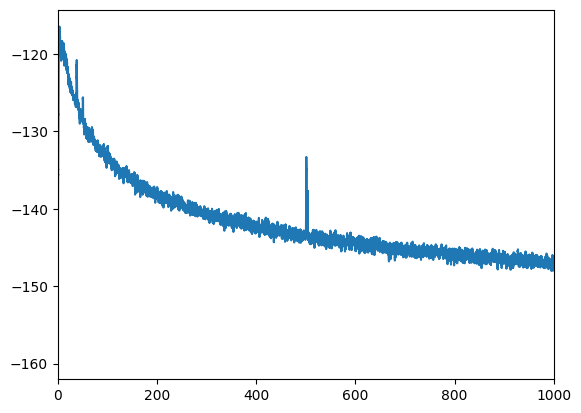

In [42]:
path = "../samples/circle8_silence.wav"

def moving_average(a, n=3):
    ret = np.cumsum(a, dtype=float)
    ret[n:] = ret[n:] - ret[:-n]
    res = np.zeros(len(a))
    res[n-1:] = ret[n - 1:] / n
    res[:n-1] = np.cumsum(a[:n-1]) / (np.arange(n-1) + 1)
    return res

x, sr = sf.read(path, always_2d=True)

n, m = x.shape
x = x[:,0]
x = x[25*sr:150*sr]
n = len(x)
t = np.arange(n) / sr

def todb(x):
    return np.log10(x)*10

print(todb(np.mean(x*x)))

plt.plot(np.fft.rfftfreq(n, 1/sr), todb(moving_average(np.abs(np.fft.rfft(x)/n)**2, 100)))
plt.xlim([0, 1000])


display(Audio(x[:5*sr], rate=sr))